# Notebook 01 — Data Loading & Exploratory Data Analysis

## Purpose
Load and explore the datasets before any preprocessing or model training.

## Dataset Modes
This notebook supports two modes controlled by the `DATASET_MODE` flag:

| Mode | Dataset | Size | Use When |
|------|---------|------|----------|
| `"dev"` | `Devika03/Research_Paper_Summarization_Dataset` | 334 rows, ~1 MB | Local laptop development |
| `"full"` | `ccdv/arxiv-summarization` + `ccdv/pubmed` | ~334K rows, ~15 GB | HPC full training runs |

**Change only the `DATASET_MODE` variable in Cell 2 — nothing else needs to change.**

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
#  GLOBAL CONFIG — change DATASET_MODE here only
# ══════════════════════════════════════════════════════════════════════════════

DATASET_MODE = "dev"   # "dev" = Devika03 (laptop) | "full" = arXiv+PubMed (HPC)
SEED = 42

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from dotenv import load_dotenv
from transformers import AutoTokenizer

# Load .env for cache directory and API keys
load_dotenv()

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)

# Plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)

# Dataset cache location (set HF_DATASETS_CACHE in your .env)
cache_dir = os.environ.get("HF_DATASETS_CACHE", None)
print(f"Dataset mode  : {DATASET_MODE}")
print(f"Cache dir     : {cache_dir or 'HuggingFace default (~/.cache)'}")
print(f"Seed          : {SEED}")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "d:\H M Lahiru B H\Education\Faculty of Engineering\7 - Semester 7\EC 7203 (Advance AI)\Project\research-summarizer\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "d:\H M Lahiru B H\Education\Faculty of Engineering\7 - Semester 7\EC 7203 (Advance AI)\Project\research-summarizer\.venv\Lib\site-packages\traitlets\config\application.py", line 1082, in launch

Dataset mode  : dev
Cache dir     : F:/huggingface/.cache
Seed          : 42


## 1. Dataset Definitions

Each mode defines its own loader config. The rest of the notebook
uses the unified `datasets` and `field_map` objects — so nothing
downstream needs to know which mode is active.

In [3]:
# ── Dataset configs ────────────────────────────────────────────────────────────

DEV_CONFIG = {
    "name": "Devika03/Research_Paper_Summarization_Dataset",
    # article equivalent = Abstract + Conclusion concatenated
    # summary equivalent = Summarization
    # domain  equivalent = Topic column mapped to General / Medical
    "article_field"  : None,        # constructed manually — see loader below
    "summary_field"  : "Summarization",
    "domain_field"   : "Topic",
    "domain_map"     : {
        "Medical Data Analysis"              : "Medical",
        "Natural Language Processing"        : "General",
        "Deep Learning and Machine Learning" : "General",
        "Artificial Neural Network"          : "General",
    },
    "single_split": True,           # only a train split exists
}

FULL_CONFIG = {
    "arxiv": {
        "name"          : "ccdv/arxiv-summarization",
        "article_field" : "article",
        "summary_field" : "abstract",
        "domain_label"  : "General",
    },
    "pubmed": {
        "name"          : "ccdv/pubmed",
        "article_field" : "article",
        "summary_field" : "abstract",
        "domain_label"  : "Medical",
    },
}

print("Dataset configs defined.")

Dataset configs defined.


## 2. Load Datasets

The loader normalises both modes into a shared format:

```python
{
  "article"  : str,   # full input text
  "summary"  : str,   # reference summary (ground truth)
  "domain"   : str,   # "General" or "Medical"
}
```

This unified schema is used in every subsequent notebook.

In [4]:
def load_and_normalise(mode: str, cache_dir: str = None) -> dict:
    """
    Load datasets and normalise them into a unified schema.

    Unified schema per example:
        - article (str): full input text
        - summary (str): reference/target summary
        - domain  (str): "General" or "Medical"

    Args:
        mode (str): "dev" for Devika03, "full" for arXiv + PubMed.
        cache_dir (str): Optional HuggingFace cache directory.

    Returns:
        dict: Keys are split names ("train", "validation", "test").
              Each value is a list of dicts with keys: article, summary, domain.
    """

    if mode == "dev":
        print(f"Loading {DEV_CONFIG['name']} ...")
        raw = load_dataset(DEV_CONFIG["name"], cache_dir=cache_dir)["train"]

        normalised = []
        for row in raw:
            # Skip rows with null fields
            if not row.get("Abstract") or not row.get("Summarization"):
                continue

            article = (
                str(row.get("Abstract", "") or "") + " " +
                str(row.get("Conclusion", "") or "")
            ).strip()
            summary = str(row["Summarization"]).strip()
            topic   = str(row.get("Topic", "") or "")
            domain  = DEV_CONFIG["domain_map"].get(topic, "General")

            normalised.append({
                "article" : article,
                "summary" : summary,
                "domain"  : domain,
                "title"   : str(row.get("Paper Title", "") or ""),
                "keywords": str(row.get("Key Words", "") or ""),
            })

        # Manually create splits (80% train / 10% val / 10% test)
        random.shuffle(normalised)
        n = len(normalised)
        n_train = int(n * 0.8)
        n_val   = int(n * 0.1)

        splits = {
            "train"     : normalised[:n_train],
            "validation": normalised[n_train : n_train + n_val],
            "test"      : normalised[n_train + n_val :],
        }
        print(f"Loaded {n} rows → train={len(splits['train'])}, "
              f"val={len(splits['validation'])}, test={len(splits['test'])}")

    elif mode == "full":
        print("Loading ccdv/arxiv-summarization ...")
        arxiv = load_dataset(FULL_CONFIG["arxiv"]["name"], cache_dir=cache_dir)
        print("Loading ccdv/pubmed ...")
        pubmed = load_dataset(FULL_CONFIG["pubmed"]["name"], cache_dir=cache_dir)

        splits = {}
        for split in ["train", "validation", "test"]:
            combined = []
            for ds, cfg_key in [(arxiv, "arxiv"), (pubmed, "pubmed")]:
                cfg = FULL_CONFIG[cfg_key]
                for row in ds[split]:
                    combined.append({
                        "article" : str(row[cfg["article_field"]] or ""),
                        "summary" : str(row[cfg["summary_field"]] or ""),
                        "domain"  : cfg["domain_label"],
                        "title"   : "",
                        "keywords": "",
                    })
            splits[split] = combined
            print(f"  {split}: {len(combined):,} examples")

    else:
        raise ValueError(f"Unknown mode '{mode}'. Use 'dev' or 'full'.")

    return splits


# Run the loader
datasets = load_and_normalise(DATASET_MODE, cache_dir=cache_dir)
print("\nDataset loading complete.")

Loading Devika03/Research_Paper_Summarization_Dataset ...


'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 0c7c433f-4b8b-4b7c-b45b-b08b188df1e7)')' thrown while requesting HEAD https://huggingface.co/datasets/Devika03/Research_Paper_Summarization_Dataset/resolve/main/README.md
Retrying in 1s [Retry 1/5].


(…)summarization%20dataset%20-%20Sheet1.csv: 0.00B [00:00, ?B/s]

d:\H M Lahiru B H\Education\Faculty of Engineering\7 - Semester 7\EC 7203 (Advance AI)\Project\research-summarizer\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in F:\huggingface\home\hub\datasets--Devika03--Research_Paper_Summarization_Dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Generating train split:   0%|          | 0/334 [00:00<?, ? examples/s]

Loaded 330 rows → train=264, val=33, test=33

Dataset loading complete.


## 3. Verify Split Sizes

In [5]:
print(f"\n{'Split':<12} {'Count':>8}  {'General':>10}  {'Medical':>10}")
print("-" * 46)

for split, rows in datasets.items():
    general = sum(1 for r in rows if r["domain"] == "General")
    medical = sum(1 for r in rows if r["domain"] == "Medical")
    print(f"{split:<12} {len(rows):>8,}  {general:>10,}  {medical:>10,}")

# Expected in full mode:
if DATASET_MODE == "full":
    print("\nExpected (full mode):")
    print("  train      ~323K  (203K general + 119K medical)")
    print("  validation  ~13K  (6.4K + 6.6K)")
    print("  test        ~13K  (6.4K + 6.6K)")
else:
    print(f"\nDev mode: {len(datasets['train']) + len(datasets['validation']) + len(datasets['test'])} "
          f"total rows split 80/10/10 from Devika03.")


Split           Count     General     Medical
----------------------------------------------
train             264         206          58
validation         33          29           4
test               33          24           9

Dev mode: 330 total rows split 80/10/10 from Devika03.


## 4. Inspect Fields

Check for null or empty values and preview the unified schema.

In [6]:
def check_nulls(rows: list, split_name: str):
    """
    Check for empty article or summary fields in a split.

    Args:
        rows (list): List of normalised example dicts.
        split_name (str): Name of the split (for display).

    Returns:
        None
    """
    empty_articles = sum(1 for r in rows if not r["article"].strip())
    empty_summaries = sum(1 for r in rows if not r["summary"].strip())
    print(f"  [{split_name}]  empty articles: {empty_articles}  "
          f"empty summaries: {empty_summaries}")


print("Null check:")
for split, rows in datasets.items():
    check_nulls(rows, split)

# Preview one example from train
print("\n── Sample example from train split ──────────────────────────────")
sample = datasets["train"][0]
for key, val in sample.items():
    preview = str(val)[:300] + ("..." if len(str(val)) > 300 else "")
    print(f"\n[{key.upper()}]\n{preview}")

Null check:
  [train]  empty articles: 0  empty summaries: 0
  [validation]  empty articles: 0  empty summaries: 0
  [test]  empty articles: 0  empty summaries: 0

── Sample example from train split ──────────────────────────────

[ARTICLE]
Machine learning approaches were introduced for better or comparable predictive ability
than statistical analysis to predict postoperative outcomes. We sought to compare the performance of
machine learning approaches with that of logistic regression analysis to predict acute kidney injury
after c...

[SUMMARY]
The study compared machine learning approaches with logistic regression analysis to predict acute kidney injury (AKI) after cardiac surgery. They retrospectively reviewed 2010 patients and obtained baseline medical condition, intraoperative anesthesia, and surgery-related data. The following machine...

[DOMAIN]
Medical

[TITLE]
Derivation and Validation of Machine Learning
Approaches to Predict Acute Kidney Injury after
.ardiac Surgery

[KEYW

## 5. Token Length Distributions

We tokenise a sample to understand input/output lengths.
This is important because:
- **LED** handles up to 16,384 tokens — designed for full research papers
- **PEGASUS** uses up to 1,024 tokens
- BART would truncate at 1,024 tokens, losing most of a paper — this is
  why we chose LED over BART for the general domain

In `dev` mode we tokenise all available examples.
In `full` mode we sample 2,000 per domain for speed.

In [7]:
TOKENIZER_NAME = (
    "allenai/led-large-16384" if DATASET_MODE == "full"
    else "facebook/bart-base"   # lightweight stand-in for dev mode
)

print(f"Loading tokenizer: {TOKENIZER_NAME} ...")
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
print("Tokenizer loaded.\n")

SAMPLE_SIZE = len(datasets["train"]) if DATASET_MODE == "dev" else 2000


def tokenize_lengths(rows: list, field: str, sample_size: int) -> list:
    """
    Compute token lengths for a field across a sample of rows.

    Args:
        rows (list): List of normalised example dicts.
        field (str): Field name to tokenize ("article" or "summary").
        sample_size (int): How many rows to sample.

    Returns:
        list[int]: Token counts.
    """
    sample = random.sample(rows, min(sample_size, len(rows)))
    lengths = []
    for row in sample:
        tokens = tokenizer(
            row[field],
            truncation=False,
            add_special_tokens=False,
        )["input_ids"]
        lengths.append(len(tokens))
    return lengths


print("Computing token lengths (may take a moment) ...")
train_rows = datasets["train"]

article_lengths = tokenize_lengths(train_rows, "article", SAMPLE_SIZE)
summary_lengths = tokenize_lengths(train_rows, "summary", SAMPLE_SIZE)

print("Done.\n")

for label, lengths in [("Articles", article_lengths), ("Summaries", summary_lengths)]:
    arr = np.array(lengths)
    print(f"{label:<12}  mean={arr.mean():.0f}  median={np.median(arr):.0f}  "
          f"p95={np.percentile(arr, 95):.0f}  max={arr.max():.0f}")

Loading tokenizer: facebook/bart-base ...


d:\H M Lahiru B H\Education\Faculty of Engineering\7 - Semester 7\EC 7203 (Advance AI)\Project\research-summarizer\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

d:\H M Lahiru B H\Education\Faculty of Engineering\7 - Semester 7\EC 7203 (Advance AI)\Project\research-summarizer\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in F:\huggingface\home\hub\models--facebook--bart-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded.

Computing token lengths (may take a moment) ...
Done.

Articles      mean=498  median=464  p95=839  max=1148
Summaries     mean=138  median=132  p95=199  max=310


## 5. Sample Inspection

Reading raw samples is the most important sanity check.
We print 5 examples from each dataset — truncated for readability — to confirm
the `article` field contains full paper body text and `abstract` contains
the reference summary we'll train against.

In [8]:
def print_samples(rows, split_name, n=5, article_preview_chars=600, summary_preview_chars=400):
    """
    Print n sample input-output pairs from a list of normalised rows.

    Args:
        rows (list): Normalised example dicts with keys: article, summary, domain.
        split_name (str): Name of the split (for display).
        n (int): Number of samples to print.
        article_preview_chars (int): Max characters to show for the article.
        summary_preview_chars (int): Max characters to show for the summary.

    Returns:
        None
    """
    print(f"\n{'='*70}")
    print(f"  {split_name.upper()} — {n} random samples")
    print(f"{'='*70}")

    sample = random.sample(rows, min(n, len(rows)))

    for i, row in enumerate(sample, 1):
        print(f"\n── Sample {i}  [domain: {row['domain']}] {'─'*35}")
        if row.get("title"):
            print(f"[TITLE]\n{row['title']}")
        print(f"\n[ARTICLE — first {article_preview_chars} chars]")
        print(row["article"][:article_preview_chars].strip())
        print("...")
        print(f"\n[SUMMARY — first {summary_preview_chars} chars]")
        print(row["summary"][:summary_preview_chars].strip())
        print()


# In dev mode: use the unified datasets dict
# In full mode: this same function still works since we normalised everything
print_samples(datasets["train"], "train split")
print_samples(datasets["test"],  "test split")


  TRAIN SPLIT — 5 random samples

── Sample 1  [domain: General] ───────────────────────────────────
[TITLE]
Concurrence of big data analytics and healthcare: A systematic review

[ARTICLE — first 600 chars]
The application of Big Data analytics in healthcare has immense potential for improving the quality of care, reducing waste and error, and reducing the cost of care. This systematic review of literature aims to determine the scope of Big Data analytics in healthcare including its applications and challenges in its adoption in healthcare. It also intends to identify the strategies to overcome the challenges. A systematic search of the articles was carried out on five major scientific databases: ScienceDirect, PubMed, Emerald, IEEE Xplore and Taylor & Francis. The articles on Big Data analytics
...

[SUMMARY — first 400 chars]
This systematic review of literature explores the potential and challenges of applying Big Data analytics in healthcare. The review considers articles publish

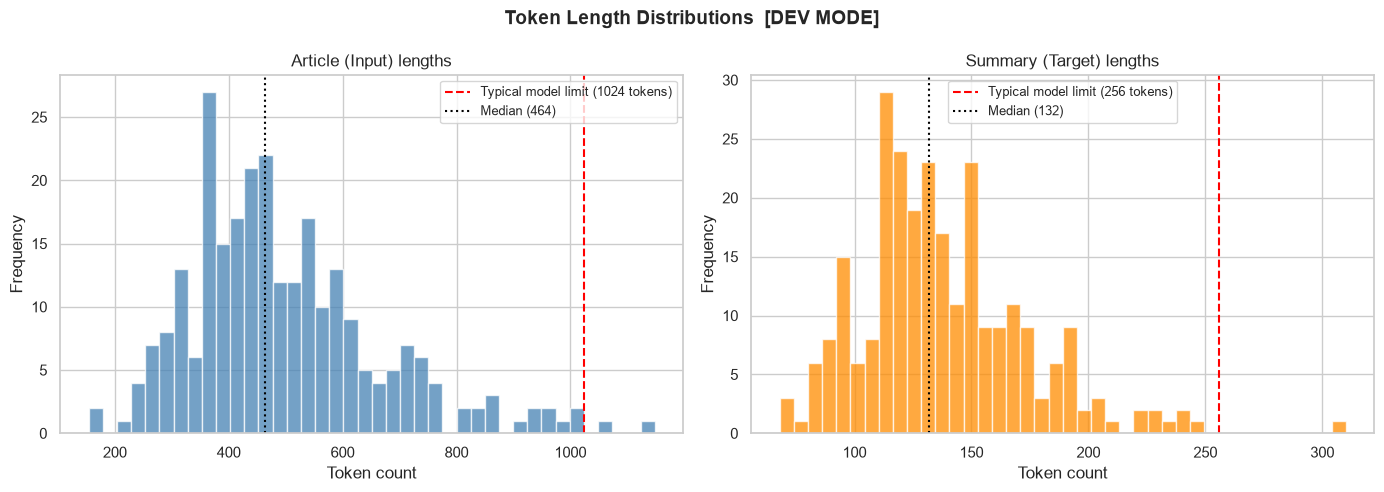

Saved → results/token_length_distributions.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    f"Token Length Distributions  [{DATASET_MODE.upper()} MODE]",
    fontsize=14, fontweight="bold"
)

for ax, lengths, title, limit, color in [
    (axes[0], article_lengths, "Article (Input) lengths",  1024, "steelblue"),
    (axes[1], summary_lengths, "Summary (Target) lengths", 256,  "darkorange"),
]:
    ax.hist(lengths, bins=40, color=color, alpha=0.75, edgecolor="white")
    ax.axvline(limit, color="red", linestyle="--", linewidth=1.5,
               label=f"Typical model limit ({limit} tokens)")
    ax.axvline(np.median(lengths), color="black", linestyle=":",
               linewidth=1.5, label=f"Median ({int(np.median(lengths))})")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Token count")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)

plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/token_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → results/token_length_distributions.png")

## 6. Domain Distribution

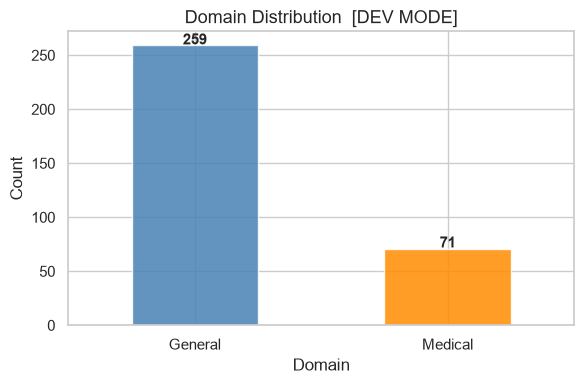

General    259
Medical     71


In [10]:
all_rows = (
    datasets["train"] + datasets["validation"] + datasets["test"]
)

domain_counts = pd.Series([r["domain"] for r in all_rows]).value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
domain_counts.plot(kind="bar", ax=ax, color=["steelblue", "darkorange"],
                   edgecolor="white", alpha=0.85)
ax.set_title(f"Domain Distribution  [{DATASET_MODE.upper()} MODE]", fontsize=13)
ax.set_xlabel("Domain")
ax.set_ylabel("Count")
ax.set_xticklabels(domain_counts.index, rotation=0)
for i, v in enumerate(domain_counts):
    ax.text(i, v + 1, f"{v:,}", ha="center", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("../results/domain_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(domain_counts.to_string())

## 7. Sample Inspection

Five examples from the test split — the most important manual sanity check.

In [11]:
def print_samples(rows: list, split_name: str, n: int = 5):
    """
    Print n sample input-output pairs from a list of normalised rows.

    Args:
        rows (list): Normalised example dicts.
        split_name (str): Name of the split (for display).
        n (int): Number of samples to print.

    Returns:
        None
    """
    print(f"\n{'='*68}")
    print(f"  {split_name.upper()} — {n} random samples")
    print(f"{'='*68}")
    sample = random.sample(rows, min(n, len(rows)))
    for i, row in enumerate(sample, 1):
        print(f"\n── Sample {i}  [domain: {row['domain']}] {'─'*35}")
        if row.get("title"):
            print(f"Title   : {row['title'][:120]}")
        print(f"Article : {row['article'][:400].strip()} ...")
        print(f"Summary : {row['summary'][:300].strip()} ...")


print_samples(datasets["test"], "test split")


  TEST SPLIT — 5 random samples

── Sample 1  [domain: General] ───────────────────────────────────
Title   : Adapting the Neural Encoder-Decoder Framework from Single to
Multi-Document Summarization
Article : Generating a text abstract from a set of documents remains a challenging task. The neural
encoder-decoder framework has recently been
exploited to summarize single documents, but
its success can in part be attributed to the availability of large parallel data automatically acquired from the Web. In contrast, parallel data
for multi-document summarization are scarce
and costly to obtain. There i ...
Summary : Generating a summary from multiple documents is challenging due to the lack of parallel data. This paper presents a novel adaptation method that combines an extractive summarization algorithm with an abstractive encoder-decoder model to generate summaries from multiple documents. The method uses the ...

── Sample 2  [domain: General] ───────────────────────────────────
T

## 8. Save Unified Dataset to Disk

We save the normalised splits as JSON so every subsequent notebook
can load them directly without re-running this loader.
This also means the HPC run just needs this notebook to have run once.

In [12]:
import json

output_dir = f"../data/processed_{DATASET_MODE}"
os.makedirs(output_dir, exist_ok=True)

for split, rows in datasets.items():
    path = os.path.join(output_dir, f"{split}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(rows, f, ensure_ascii=False, indent=2)
    print(f"Saved {len(rows):>5,} rows → {path}")

print(f"\nAll splits saved to {output_dir}/")
print("Next notebooks will load from here using DATASET_MODE =", DATASET_MODE)

Saved   264 rows → ../data/processed_dev\train.json
Saved    33 rows → ../data/processed_dev\validation.json
Saved    33 rows → ../data/processed_dev\test.json

All splits saved to ../data/processed_dev/
Next notebooks will load from here using DATASET_MODE = dev


## ✅ Phase 1 Complete — Gate Check

- [ ] Dataset loaded without errors
- [ ] All three splits present (train / validation / test)
- [ ] No empty article or summary fields
- [ ] Domain distribution looks reasonable (General + Medical both present)
- [ ] Token length plots generated and saved
- [ ] 5 sample pairs look sensible
- [ ] Processed splits saved to `data/processed_dev/` (or `data/processed_full/`)

**Switching to HPC tomorrow:**
1. Change `DATASET_MODE = "full"` in Cell 2
2. Re-run the notebook — everything else is automatic
3. Processed full splits will be saved to `data/processed_full/`

Proceed to `02_preprocessing_pipeline.ipynb`.